In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Load and clean dataset
df = pd.read_csv('Titanic-Dataset.csv')
df = df.fillna({
    'Age': df['Age'].median(),
    'Cabin': 'Unknown',
    'Embarked': df['Embarked'].mode()[0]
})

# Extract Deck and encode categorical features
df['Deck'] = df['Cabin'].str[0]
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df_model = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df_model = pd.get_dummies(df_model, columns=['Embarked', 'Deck'], drop_first=True, dtype=int)

X = df_model.drop(columns=['Survived'])
y = df_model['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Tree Depth: 25
Train Accuracy: 0.9831
Test Accuracy:  0.7989


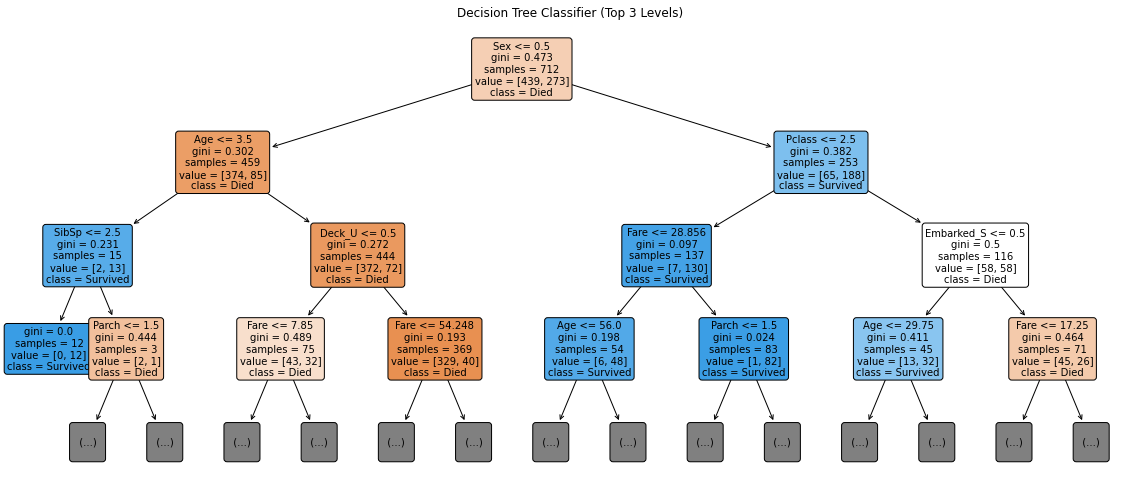

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Train unconstrained Decision Tree
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

print(f"Tree Depth: {dt_full.get_depth()}")
print(f"Train Accuracy: {accuracy_score(y_train, dt_full.predict(X_train)):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, dt_full.predict(X_test)):.4f}")

# Visualize top 3 levels of the tree
plt.figure(figsize=(16, 7))
plot_tree(
    dt_full,
    max_depth=3,
    feature_names=list(X.columns),
    class_names=['Died', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier (Top 3 Levels)')
plt.tight_layout()
plt.show()

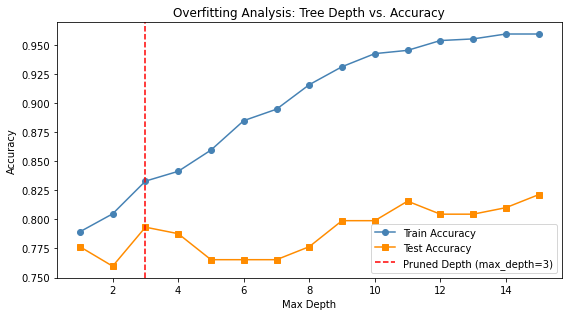

Pruned DT Train Accuracy: 0.8329
Pruned DT Test Accuracy:  0.7933


In [3]:
depths = range(1, 16)
train_acc, test_acc = [], []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, clf.predict(X_train)))
    test_acc.append(accuracy_score(y_test, clf.predict(X_test)))

# Plot overfitting curve
plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_acc, marker='o', label='Train Accuracy', color='steelblue')
plt.plot(depths, test_acc, marker='s', label='Test Accuracy', color='darkorange')
plt.axvline(3, color='red', linestyle='--', label='Pruned Depth (max_depth=3)')
plt.title('Overfitting Analysis: Tree Depth vs. Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Train pruned Decision Tree
dt_pruned = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_pruned.fit(X_train, y_train)

print(f"Pruned DT Train Accuracy: {accuracy_score(y_train, dt_pruned.predict(X_train)):.4f}")
print(f"Pruned DT Test Accuracy:  {accuracy_score(y_test, dt_pruned.predict(X_test)):.4f}")

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42)
rf.fit(X_train, y_train)

print(f"Unconstrained DT Test Accuracy: {accuracy_score(y_test, dt_full.predict(X_test)):.4f}")
print(f"Pruned DT Test Accuracy:        {accuracy_score(y_test, dt_pruned.predict(X_test)):.4f}")
print(f"Random Forest Train Accuracy:   {accuracy_score(y_train, rf.predict(X_train)):.4f}")
print(f"Random Forest Test Accuracy:    {accuracy_score(y_test, rf.predict(X_test)):.4f}")

Unconstrained DT Test Accuracy: 0.7989
Pruned DT Test Accuracy:        0.7933
Random Forest Train Accuracy:   0.9073
Random Forest Test Accuracy:    0.8101


Top 8 Feature Importances:
 Sex           0.3526
Fare          0.1823
Age           0.1374
Pclass        0.0888
Deck_U        0.0785
SibSp         0.0429
Parch         0.0360
Embarked_S    0.0252
dtype: float64


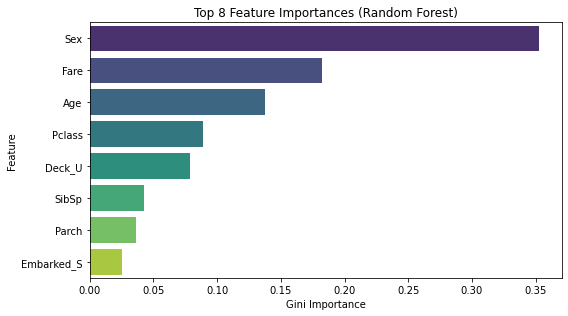

In [5]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 8 Feature Importances:\n", importances.head(8).round(4))

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importances.head(8).values, y=importances.head(8).index, palette='viridis')
plt.title('Top 8 Feature Importances (Random Forest)')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import cross_val_score

models = {
    'Unconstrained Decision Tree': dt_full,
    'Pruned Decision Tree (depth=3)': dt_pruned,
    'Random Forest (200 trees)': rf
}

print("--- 5-Fold Cross-Validation Accuracy ---")
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(f"{name:32s} -> Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- 5-Fold Cross-Validation Accuracy ---
Unconstrained Decision Tree      -> Mean: 0.7969 (+/- 0.0352)
Pruned Decision Tree (depth=3)   -> Mean: 0.8058 (+/- 0.0145)
Random Forest (200 trees)        -> Mean: 0.8227 (+/- 0.0343)
